In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(
    "https://raw.githubusercontent.com/raine0021/SpaceX-Data-Science-Capstone-/main/SpaceX_Cleaned_Data.csv"
)

print("Dataset loaded successfully!")
print("Total launches:", len(df))
display(df.head())

Dataset loaded successfully!
Total launches: 90


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


In [6]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    ),
    "Support Vector Machine": SVC()
}

results = []

for name, classifier in models.items():
    classifier.fit(X_train, y_train)
    predictions = classifier.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    results.append({
        "Model": name,
        "Accuracy": round(accuracy * 100, 2)
    })

results_df = pd.DataFrame(results)
display(results_df.sort_values("Accuracy", ascending=False))


,Model,Accuracy
2,Random Forest,94.44
1,Decision Tree,88.89
3,Support Vector Machine,77.78
0,Logistic Regression,72.22


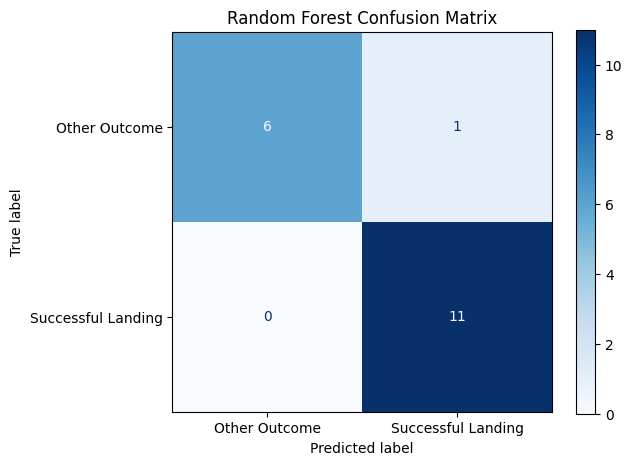

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.86      0.92         7
           1       0.92      1.00      0.96        11

    accuracy                           0.94        18
   macro avg       0.96      0.93      0.94        18
weighted avg       0.95      0.94      0.94        18



In [7]:

from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

# Train Random Forest
best_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

best_model.fit(X_train, y_train)
best_predictions = best_model.predict(X_test)

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Other Outcome", "Successful Landing"],
    cmap="Blues"
)

plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.savefig("SpaceX_Random_Forest_Confusion_Matrix.png", dpi=300)
plt.show()

print("Random Forest Classification Report:")
print(classification_report(y_test, best_predictions))


In [9]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

scores = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", np.round(scores * 100, 2))
print(f"Average CV accuracy: {scores.mean() * 100:.2f}%")


Cross-validation scores: [86.67 66.67 78.57 92.86 85.71]
Average CV accuracy: 82.10%


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Select the features used for prediction
features = ["FlightNumber", "PayloadMass", "Flights", "ReusedCount"]

X = df[features]
y = df["Class"]

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Machine learning data prepared successfully!")


Training records: 72
Testing records: 18
Machine learning data prepared successfully!


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Create and train the prediction model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predict landing outcomes
y_pred = model.predict(X_test)

# Evaluate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model trained successfully!")
print(f"Prediction Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Model trained successfully!
Prediction Accuracy: 72.22%

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.71      0.67         7
           1       0.80      0.73      0.76        11

    accuracy                           0.72        18
   macro avg       0.71      0.72      0.71        18
weighted avg       0.73      0.72      0.72        18



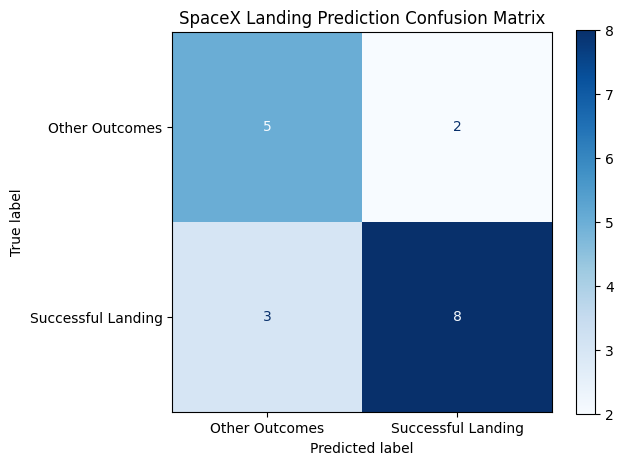

Confusion matrix saved successfully!


In [ ]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Other Outcomes", "Successful Landing"],
    cmap="Blues"
)

plt.title("SpaceX Landing Prediction Confusion Matrix")
plt.tight_layout()
plt.savefig("SpaceX_Confusion_Matrix.png", dpi=300)
plt.show()

print("Confusion matrix saved successfully!")
